<a href="https://colab.research.google.com/github/jinatyeasmin/MCA-DATA-SCIENCE/blob/main/Food-data/fastfood_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/content/drive/MyDrive/ML/fastfood.csv")
print(df.shape)
df.head()

(515, 17)


,restaurant,item,calories,cal_fat,total_fat,sat_fat,trans_fat,cholesterol,sodium,total_carb,fiber,sugar,protein,vit_a,vit_c,calcium,salad
0,Mcdonalds,Artisan Grilled Chicken Sandwich,380,60,7,2.0,0.0,95,1110,44,3.0,11,37.0,4.0,20.0,20.0,Other
1,Mcdonalds,Single Bacon Smokehouse Burger,840,410,45,17.0,1.5,130,1580,62,2.0,18,46.0,6.0,20.0,20.0,Other
2,Mcdonalds,Double Bacon Smokehouse Burger,1130,600,67,27.0,3.0,220,1920,63,3.0,18,70.0,10.0,20.0,50.0,Other
3,Mcdonalds,Grilled Bacon Smokehouse Chicken Sandwich,750,280,31,10.0,0.5,155,1940,62,2.0,18,55.0,6.0,25.0,20.0,Other
4,Mcdonalds,Crispy Bacon Smokehouse Chicken Sandwich,920,410,45,12.0,0.5,120,1980,81,4.0,18,46.0,6.0,20.0,20.0,Other


## Data Cleaning

In [5]:
print(df.isnull().sum())

for c in ["fiber", "protein"]:
    df[c] = df[c].fillna(df[c].median())
for c in ["vit_a", "vit_c", "calcium"]:
    df[c] = df[c].fillna(0)


print(df["salad"].value_counts())
df["food_type"] = df["item"].str.contains("salad", case=False).map({True: "Salad", False: "Other"})
print(df["food_type"].value_counts())

restaurant       0
item             0
calories         0
cal_fat          0
total_fat        0
sat_fat          0
trans_fat        0
cholesterol      0
sodium           0
total_carb       0
fiber           12
sugar            0
protein          1
vit_a          214
vit_c          210
calcium        210
salad            0
dtype: int64
salad
Other    515
Name: count, dtype: int64
food_type
Other    451
Salad     64
Name: count, dtype: int64


## Q1. Which restaurant has the highest number of food items?

restaurant
Taco Bell      115
Subway          96
Burger King     70
Mcdonalds       57
Arbys           55
Sonic           53
Dairy Queen     42
Chick Fil-A     27
Name: count, dtype: int64

Highest: Taco Bell with 115 items


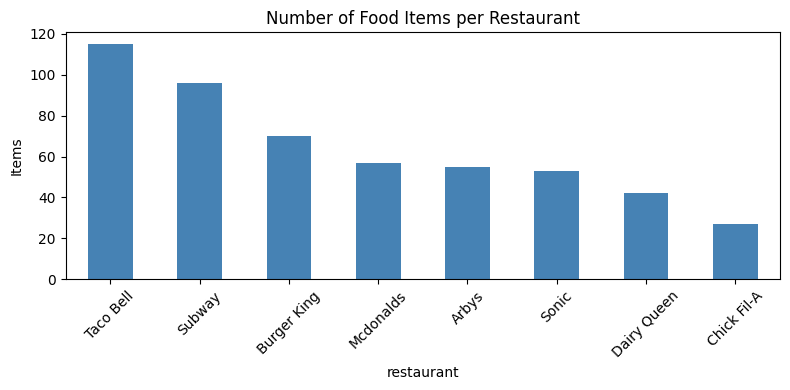

In [6]:
counts = df["restaurant"].value_counts()
print(counts)
print("\nHighest:", counts.idxmax(), "with", counts.max(), "items")

counts.plot(kind="bar", color="steelblue", figsize=(8, 4))
plt.title("Number of Food Items per Restaurant")
plt.ylabel("Items")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Q2. Top 10 items with the highest calories

 restaurant                                             item  calories
  Mcdonalds       20 piece Buttermilk Crispy Chicken Tenders      2430
  Mcdonalds                       40 piece Chicken McNuggets      1770
  Mcdonalds 10 piece Sweet N' Spicy Honey BBQ Glazed Tenders      1600
Burger King                          American Brewhouse King      1550
  Mcdonalds       12 piece Buttermilk Crispy Chicken Tenders      1510
      Sonic Garlic Parmesan Dunked Ultimate Chicken Sandwich      1350
      Sonic   Super Sonic Bacon Double Cheeseburger (w/mayo)      1280
Dairy Queen    6 Piece Chicken Strip Basket w/ Country Gravy      1260
Burger King                                       Rodeo King      1250
      Sonic          Super Sonic Double Cheeseburger W/ Mayo      1220


/tmp/ipykernel_869/2416604032.py:9: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


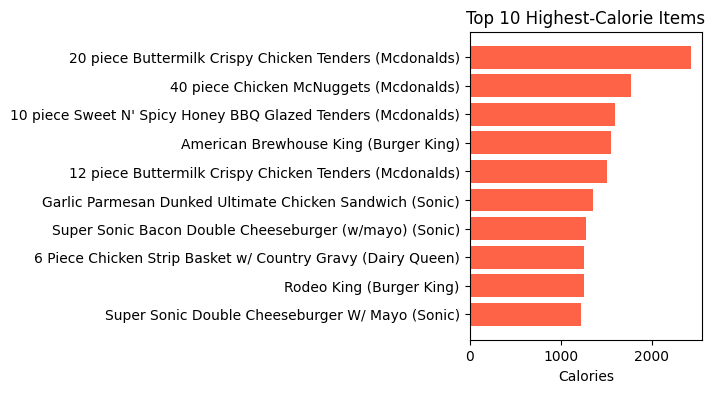

In [7]:
top_cal = df.nlargest(10, "calories")[["restaurant", "item", "calories"]]
print(top_cal.to_string(index=False))

labels = top_cal["item"] + " (" + top_cal["restaurant"] + ")"
plt.figure(figsize=(3, 4))
plt.barh(labels[::-1], top_cal["calories"][::-1], color="tomato")
plt.title("Top 10 Highest-Calorie Items")
plt.xlabel("Calories")
plt.tight_layout()
plt.show()

## Q3. Average calories per restaurant

restaurant
Mcdonalds      640.4
Sonic          631.7
Burger King    608.6
Arbys          532.7
Dairy Queen    520.2
Subway         503.0
Taco Bell      443.7
Chick Fil-A    384.4
Name: calories, dtype: float64


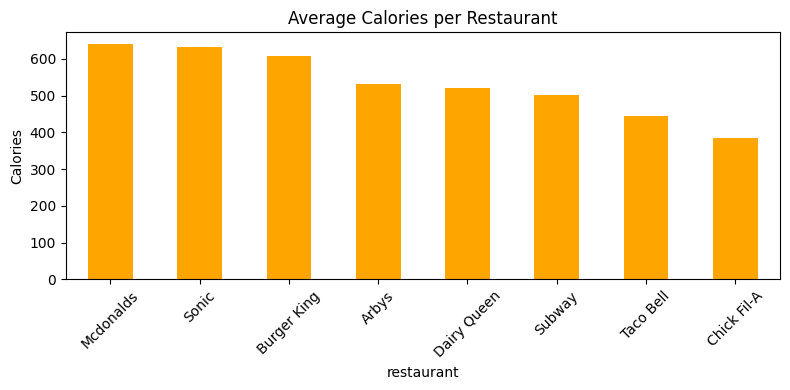

In [8]:
avg_cal = df.groupby("restaurant")["calories"].mean().sort_values(ascending=False)
print(avg_cal.round(1))

avg_cal.plot(kind="bar", color="orange", figsize=(8, 4))
plt.title("Average Calories per Restaurant")
plt.ylabel("Calories")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Q4. Restaurant with the highest average protein

restaurant
Mcdonalds      40.3
Chick Fil-A    31.7
Subway         30.3
Burger King    29.9
Arbys          29.3
Sonic          29.2
Dairy Queen    24.8
Taco Bell      17.4
Name: protein, dtype: float64

Highest average protein: Mcdonalds - 40.3 g


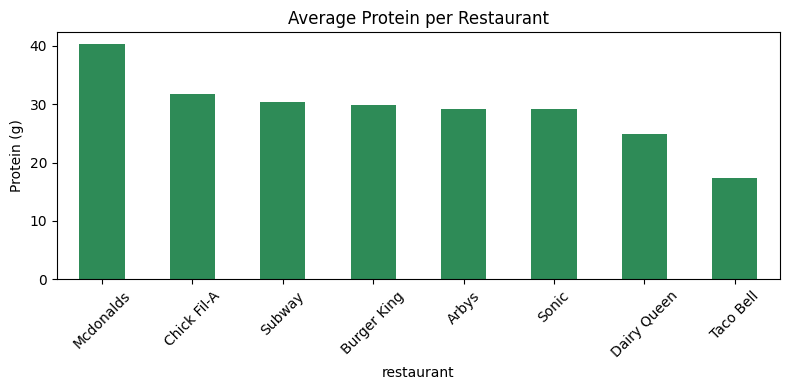

In [9]:
avg_pro = df.groupby("restaurant")["protein"].mean().sort_values(ascending=False)
print(avg_pro.round(1))
print("\nHighest average protein:", avg_pro.idxmax(), "-", round(avg_pro.max(), 1), "g")

avg_pro.plot(kind="bar", color="seagreen", figsize=(8, 4))
plt.title("Average Protein per Restaurant")
plt.ylabel("Protein (g)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Q5. Highest and lowest average total fat

restaurant
Sonic          37.6
Burger King    36.8
Mcdonalds      31.8
Dairy Queen    28.9
Arbys          27.0
Taco Bell      20.9
Subway         18.5
Chick Fil-A    16.1
Name: total_fat, dtype: float64

Highest: Sonic - 37.6 g
Lowest : Chick Fil-A - 16.1 g


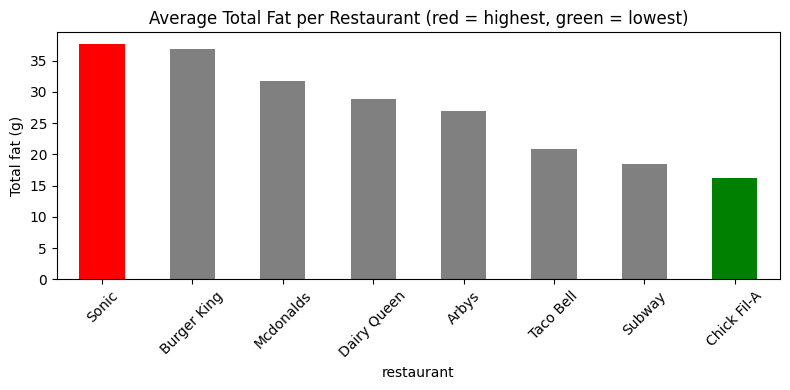

In [10]:
avg_fat = df.groupby("restaurant")["total_fat"].mean().sort_values(ascending=False)
print(avg_fat.round(1))
print("\nHighest:", avg_fat.idxmax(), "-", round(avg_fat.max(), 1), "g")
print("Lowest :", avg_fat.idxmin(), "-", round(avg_fat.min(), 1), "g")

colors = ["red" if r == avg_fat.idxmax() else "green" if r == avg_fat.idxmin() else "gray" for r in avg_fat.index]
avg_fat.plot(kind="bar", color=colors, figsize=(8, 4))
plt.title("Average Total Fat per Restaurant (red = highest, green = lowest)")
plt.ylabel("Total fat (g)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Q6. Items with the highest sugar and their calories

 restaurant                                                item  sugar  calories
  Mcdonalds    10 piece Sweet N' Spicy Honey BBQ Glazed Tenders     87      1600
  Mcdonalds     6 piece Sweet N' Spicy Honey BBQ Glazed Tenders     52       960
Burger King  Chicken, Apple & Cranberry Salad w/ Crispy Chicken     37       700
     Subway               Footlong Sweet Onion Chicken Teriyaki     36       760
  Mcdonalds     4 piece Sweet N' Spicy Honey BBQ Glazed Tenders     35       640
Burger King Chicken, Apple & Cranberry Salad w/ Grilled Chicken     34       560
Dairy Queen                                  Large Cheese Curds     30      1050
     Subway                         Footlong Corned Beef Reuben     24       940
     Subway                          Footlong Meatball Marinara     24       960
      Arbys                                     Arby-Q Sandwich     23       400


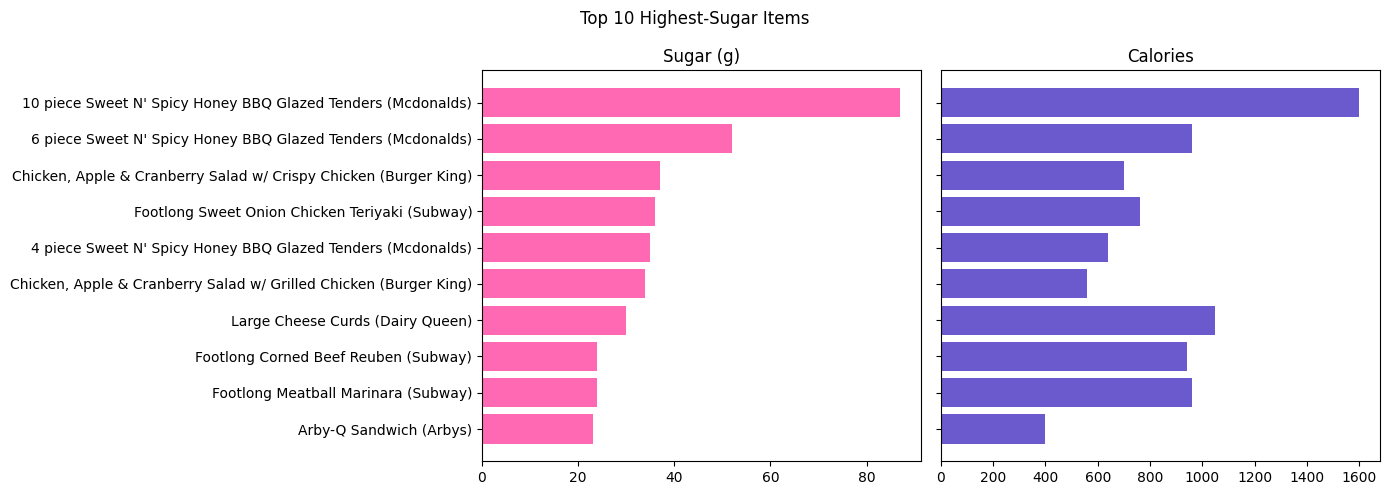

In [11]:
top_sugar = df.nlargest(10, "sugar")[["restaurant", "item", "sugar", "calories"]]
print(top_sugar.to_string(index=False))

labels = top_sugar["item"] + " (" + top_sugar["restaurant"] + ")"
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
ax[0].barh(labels[::-1], top_sugar["sugar"][::-1], color="hotpink")
ax[0].set_title("Sugar (g)")
ax[1].barh(labels[::-1], top_sugar["calories"][::-1], color="slateblue")
ax[1].set_title("Calories")
plt.suptitle("Top 10 Highest-Sugar Items")
plt.tight_layout()
plt.show()

## Q7. Salad vs other items: effect on calories, fat, carbs, protein

           calories  total_fat  total_carb  protein
food_type                                          
Other         554.1       27.4        48.7     28.6
Salad         367.8       20.5        24.0     22.9


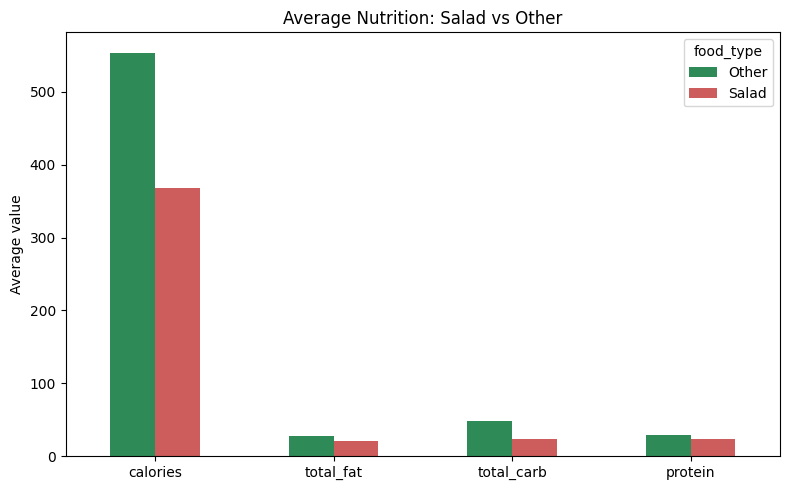

In [12]:
nutrients = ["calories", "total_fat", "total_carb", "protein"]
type_avg = df.groupby("food_type")[nutrients].mean().round(1)
print(type_avg)

type_avg.T.plot(kind="bar", figsize=(8, 5), color=["seagreen", "indianred"])
plt.title("Average Nutrition: Salad vs Other")
plt.ylabel("Average value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Q8. Best combination of low calories and high protein


             calories  protein  protein_per_100cal
restaurant                                        
Chick Fil-A    384.44    31.70                8.25
Mcdonalds      640.35    40.30                6.29
Subway         503.02    30.31                6.03
Arbys          532.73    29.25                5.49
Burger King    608.57    29.94                4.92
Dairy Queen    520.24    24.83                4.77
Sonic          631.70    29.19                4.62
Taco Bell      443.65    17.42                3.93

Best combination: Chick Fil-A


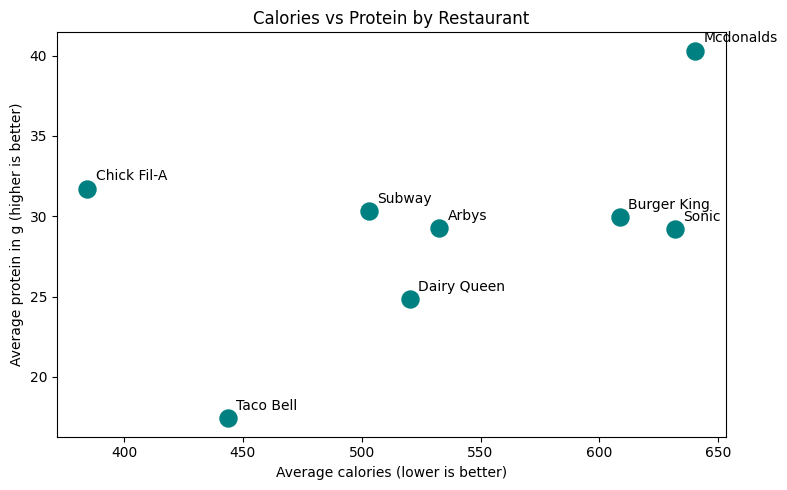

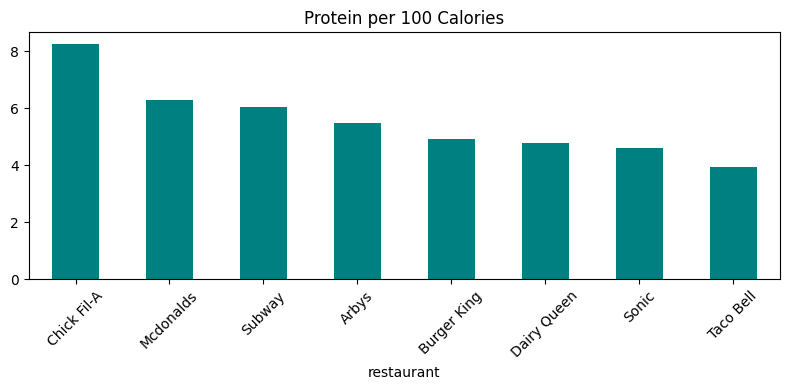

In [13]:
g = df.groupby("restaurant")[["calories", "protein"]].mean()
g["protein_per_100cal"] = g["protein"] / g["calories"] * 100
g = g.sort_values("protein_per_100cal", ascending=False)
print(g.round(2))
print("\nBest combination:", g.index[0])

plt.figure(figsize=(8, 5))
plt.scatter(g["calories"], g["protein"], s=150, color="teal")
for name, row in g.iterrows():
    plt.annotate(name, (row["calories"], row["protein"]), xytext=(6, 6), textcoords="offset points")
plt.xlabel("Average calories (lower is better)")
plt.ylabel("Average protein in g (higher is better)")
plt.title("Calories vs Protein by Restaurant")
plt.tight_layout()
plt.show()

g["protein_per_100cal"].plot(kind="bar", color="teal", figsize=(8, 4))
plt.title("Protein per 100 Calories")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Q9. Health Risk Score and the 10 least healthy items


 restaurant                                           item  health_risk_score  calories  total_fat  sat_fat  trans_fat  cholesterol  sodium
Burger King                        American Brewhouse King               80.4      1550        126     47.0        8.0          805    1820
  Mcdonalds     20 piece Buttermilk Crispy Chicken Tenders               72.5      2430        141     24.0        2.0          475    6080
      Sonic Super Sonic Bacon Double Cheeseburger (w/mayo)               50.5      1280         92     36.0        4.0          260    1630
      Sonic        Super Sonic Double Cheeseburger W/ Mayo               48.2      1220         87     34.0        4.0          245    1520
  Mcdonalds                     40 piece Chicken McNuggets               47.5      1770        107     18.0        0.5          295    3370
Burger King                                     Rodeo King               47.4      1250         82     31.0        3.5          230    2270
Burger King         

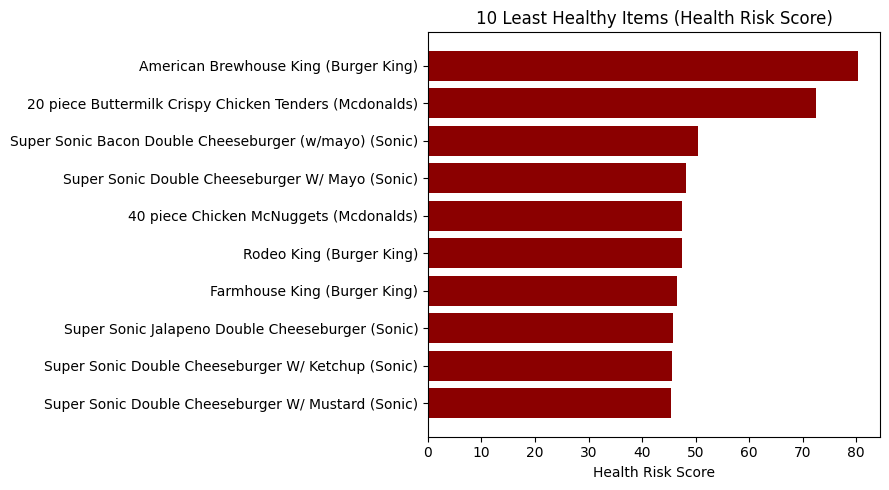

In [14]:
risk_cols = ["calories", "total_fat", "sat_fat", "trans_fat", "cholesterol", "sodium"]

scaled = (df[risk_cols] - df[risk_cols].min()) / (df[risk_cols].max() - df[risk_cols].min())
df["health_risk_score"] = scaled.mean(axis=1) * 100

worst10 = df.nlargest(10, "health_risk_score")[["restaurant", "item", "health_risk_score"] + risk_cols]
print(worst10.round(1).to_string(index=False))

labels = worst10["item"] + " (" + worst10["restaurant"] + ")"
plt.figure(figsize=(9, 5))
plt.barh(labels[::-1], worst10["health_risk_score"][::-1], color="darkred")
plt.title("10 Least Healthy Items (Health Risk Score)")
plt.xlabel("Health Risk Score")
plt.tight_layout()
plt.show()

## Q10. Healthiest overall menu


             calories  total_fat  sugar  sodium  fiber  protein  vitamins
restaurant                                                               
Arbys           532.7       27.0    7.6  1515.3    2.7     29.3       5.8
Burger King     608.6       36.8    8.2  1223.6    2.5     29.9       0.0
Chick Fil-A     384.4       16.1    4.1  1151.5    2.4     31.7      11.1
Dairy Queen     520.2       28.9    6.4  1181.8    2.8     24.8       7.5
Mcdonalds       640.4       31.8   11.1  1437.9    3.2     40.3      24.2
Sonic           631.7       37.6    6.5  1350.8    2.7     29.2       9.2
Subway          503.0       18.5   10.1  1273.0    6.6     30.3      34.5
Taco Bell       443.7       20.9    3.7  1013.9    5.7     17.4       3.1

Ranking (higher = healthier):
restaurant
Chick Fil-A    73.1
Taco Bell      70.9
Subway         61.4
Dairy Queen    44.9
Arbys          30.7
Burger King    26.3
Mcdonalds      26.2
Sonic          25.0
Name: healthy_score, dtype: float64

Healthiest menu: Chic

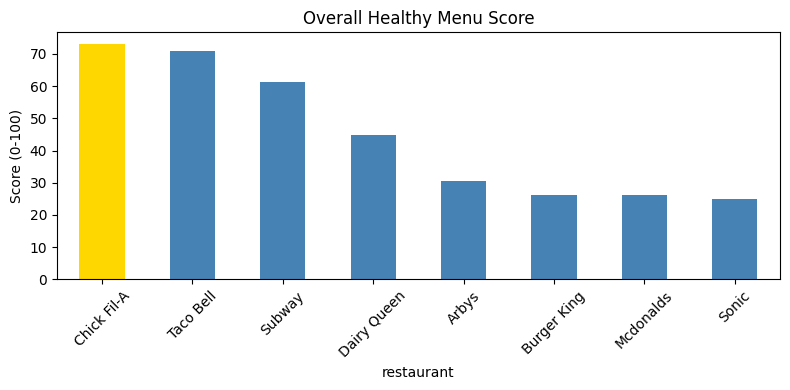

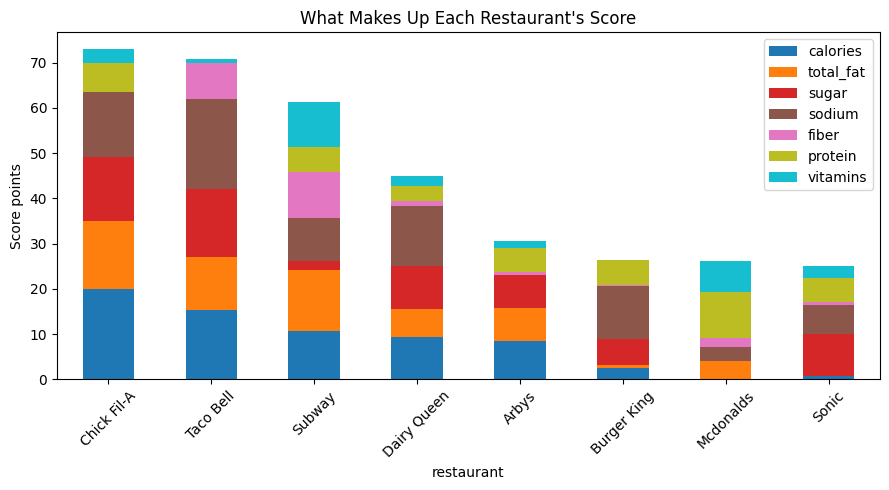

In [15]:
df["vitamins"] = df[["vit_a", "vit_c", "calcium"]].mean(axis=1)

r = df.groupby("restaurant")[["calories", "total_fat", "sugar", "sodium", "fiber", "protein", "vitamins"]].mean()
print(r.round(1))

norm = (r - r.min()) / (r.max() - r.min())
for bad in ["calories", "total_fat", "sugar", "sodium"]:
    norm[bad] = 1 - norm[bad]

weights = {"calories": 0.20, "total_fat": 0.15, "sugar": 0.15, "sodium": 0.20,
           "fiber": 0.10, "protein": 0.10, "vitamins": 0.10}

r["healthy_score"] = sum(norm[c] * w for c, w in weights.items()) * 100
ranking = r["healthy_score"].sort_values(ascending=False)
print("\nRanking (higher = healthier):")
print(ranking.round(1))
print("\nHealthiest menu:", ranking.index[0])

colors = ["gold" if x == ranking.index[0] else "steelblue" for x in ranking.index]
ranking.plot(kind="bar", color=colors, figsize=(8, 4))
plt.title("Overall Healthy Menu Score")
plt.ylabel("Score (0-100)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


contrib = pd.DataFrame({c: norm[c] * w * 100 for c, w in weights.items()}).loc[ranking.index]
contrib.plot(kind="bar", stacked=True, figsize=(9, 5), colormap="tab10")
plt.title("What Makes Up Each Restaurant's Score")
plt.ylabel("Score points")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()